In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

# 1. Load the Iris dataset
iris = load_iris()
X = iris.data
y_true = iris.target  # Saved only for evaluation/comparison, not used in clustering

# 2. Create a DataFrame for convenience
df = pd.DataFrame(X, columns=iris.feature_names)

# 3. Preprocessing: Feature Scaling
# Scaling ensures all features contribute equally to the distance metrics
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Dataset loaded and preprocessed successfully!")
print(f"Features shape: {X_scaled.shape}")

Dataset loaded and preprocessed successfully!
Features shape: (150, 4)


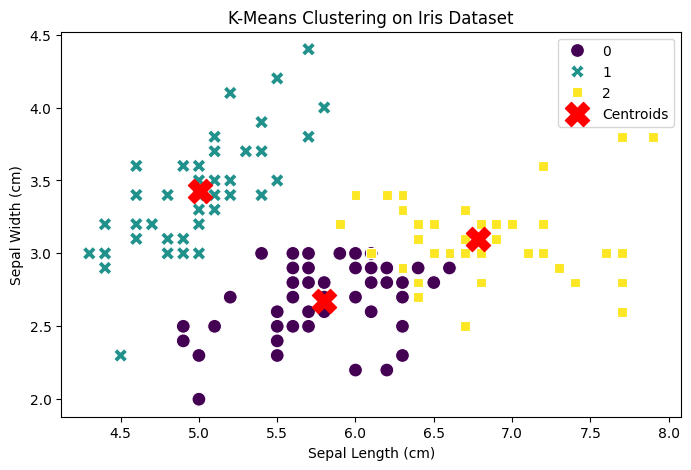

In [2]:
from sklearn.cluster import KMeans

# Apply K-Means with k=3 (since Iris has 3 distinct species)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

# Add cluster labels to dataframe for plotting
df['KMeans_Cluster'] = kmeans_labels

# Visualize K-Means Clusters (using Sepal Length vs Sepal Width)
plt.figure(figsize=(8, 5))
sns.scatterplot(x=df['sepal length (cm)'], y=df['sepal width (cm)'],
                hue=df['KMeans_Cluster'], palette='viridis', s=100, style=df['KMeans_Cluster'])
# Plot centroids (inverse transformed back to original scale if needed, or plotted directly)
centroids = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(centroids[:, 0], centroids[:, 1], s=300, c='red', marker='X', label='Centroids')
plt.title("K-Means Clustering on Iris Dataset")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")
plt.legend()
plt.show()

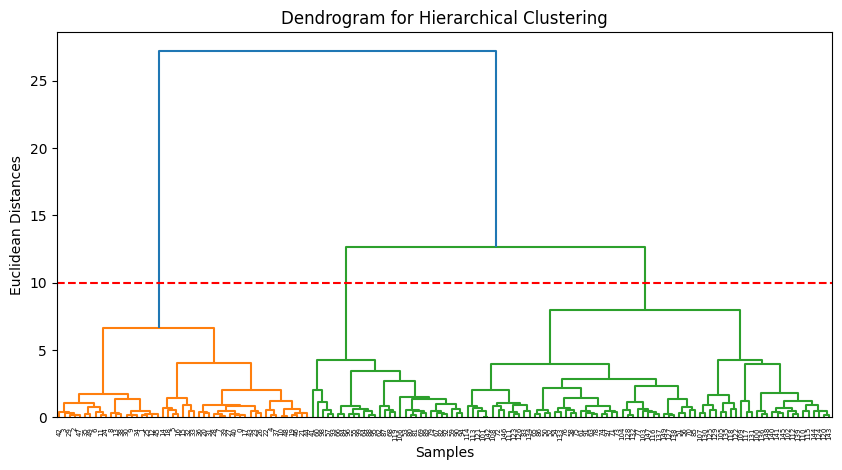

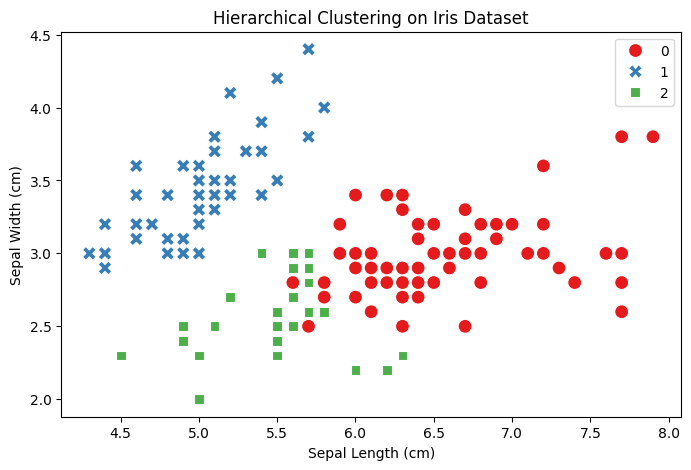

In [3]:
from sklearn.cluster import AgglomerativeClustering
import scipy.cluster.hierarchy as sch

# 1. Plot the Dendrogram to visualize hierarchy
plt.figure(figsize=(10, 5))
dendrogram = sch.dendrogram(sch.linkage(X_scaled, method='ward'))
plt.title("Dendrogram for Hierarchical Clustering")
plt.xlabel("Samples")
plt.ylabel("Euclidean Distances")
plt.axhline(y=10, color='r', linestyle='--') # Cutoff line for 3 clusters
plt.show()

# 2. Apply Agglomerative Hierarchical Clustering with 3 clusters
hierarchical = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
hierarchical_labels = hierarchical.fit_predict(X_scaled)

df['Hierarchical_Cluster'] = hierarchical_labels

# 3. Visualize Hierarchical Clusters
plt.figure(figsize=(8, 5))
sns.scatterplot(x=df['sepal length (cm)'], y=df['sepal width (cm)'],
                hue=df['Hierarchical_Cluster'], palette='Set1', s=100, style=df['Hierarchical_Cluster'])
plt.title("Hierarchical Clustering on Iris Dataset")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")
plt.legend()
plt.show()